# Multi Agent

#### Workflow
#### foundation
* Library
* Support State
* LLM
#### Node
1. Triage Node
2. Billing Node
3. Technical Node
4. General Node
5. Sentiment Node
6. Human
7. Graph
#### Graph
#### Test
1. Test 1
2. Test 2
3. Test 3

## Workflow

# Foundation

## Library

In [180]:
import operator

from typing import TypedDict, Annotated, Literal

from pydantic import BaseModel, Field

from langchain_core.tools import tool
# from langchain_core.documents import Document
from langchain_community.document_loaders import TextLoader


from langchain_ollama import ChatOllama

from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

from IPython.display import Image, display

from langchain_core.prompts import ChatPromptTemplate


## LLM

In [181]:
llm = ChatOllama(model="llama3.2:3b", temperature=0.3)

## Support State

In [182]:
class SupportState(TypedDict):

    # Customer conversation
    messages: Annotated[list, operator.add]

    # Customer information
    user_id: str

    # Sentiment
    sentiment: str

    # Department
    department: str

    # Graph routing
    next_step: str

    # Billing information
    transaction_id: str # تراکنش مالی
    subscription_status: str

    # Human response
    human_response: str

# Node

## 1.Triage Node

#### 1.Structure Output

In [183]:
class TriageDecision(BaseModel):

    department: Literal["billing", 
                        "technical",
                        "general"] = Field(description=("The department responsible for handling the customer's request."))

# ساخت Object
triage_llm = llm.with_structured_output(TriageDecision)

#### 2.Prompt

In [184]:
TRIAGE_PROMPT = """
You are the Triage Agent of a customer support system.

Your task is to classify the customer's request.

Choose exactly ONE department.

BILLING:
- payment
- subscription
- refund
- transaction
- billing problems
- subscription not working

TECHNICAL:
- software problems
- password reset
- login problems
- technical questions
- product usage problems

GENERAL:
- greetings
- general questions
- other requests

Important:
If the customer mentions subscription, payment,
refund, transaction, billing or money,
classify the request as BILLING.

Customer message:
{user_message}

Return the correct department.
"""

#### 3.Agent

In [185]:
def triage_agent(state: SupportState):

    user_message = state["messages"][0]

    prompt = TRIAGE_PROMPT.format(user_message=user_message)

    decision = triage_llm.invoke(prompt)

    return {"department": decision.department,
            "next_step": decision.department}

#### 4.Router

In [186]:
def route_from_triage(state: SupportState):

    return state["next_step"]

## 2.Billing Node

#### 1.Tool

In [187]:
@tool
def check_subscription_status(user_id):
    """
    Check the subscription status of a customer.
    """

    subscriptions = {

        "12345": "expired",

        "67890": "active",

        "11111": "cancelled",

        "22222": "active"
    }

    status = subscriptions.get(user_id, "user_not_found")

    return status

#### 2.Prompt

In [188]:
BILLING_PROMPT = """
You are the Billing Support Agent.

Handle only:
- subscriptions
- payments
- refunds
- transactions

Customer message:
{user_message}

Customer ID:
{user_id}

Tool result:
{tool_result}

Rules:
1. Give a short customer-facing answer.
2. If the subscription is expired, clearly state that.
3. Do not invent information.
4. Do not answer technical questions.
5. Do not mention internal tools.
6. Avoid unnecessary explanations.

Return only the final customer-facing answer.
"""

#### 3.Agent

In [ ]:
def billing_agent(state: SupportState):

    user_id = state.get("user_id", "")
    user_message = state["messages"][0]

    status = check_subscription_status.invoke({"user_id": user_id})

    prompt = BILLING_PROMPT.format(user_message=user_message,
                                            user_id=user_id,
                                            tool_result=status)

    response = llm.invoke(prompt)

    return {"messages": [response.content],
            "subscription_status": status,
            "department": "billing",
            "next_step": "sentiment"}

## 3.Technical Node

#### 1. RAG

* Documents

In [228]:
documents = []

documents.extend(TextLoader("technical_docs/password_reset.txt").load())

documents.extend(TextLoader("technical_docs/login_guide.txt").load())

documents.extend(TextLoader("technical_docs/security_guide.txt").load())



* Embeddings

In [229]:
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2",
                                    model_kwargs={"device": "cpu"},
                                    encode_kwargs={"normalize_embeddings": False})

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

* Vector Store

In [230]:
vectorstore = FAISS.from_documents(documents, embeddings)

* Retriever

In [231]:
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 3})

#### 2.Tool

In [232]:
@tool
def search_knowledge_base(query):
    """
    Search the technical knowledge base.
    """

    docs = retriever.invoke(query)

    if not docs:

        return "NO_RELEVANT_INFORMATION"

    # context = "\n\n".join(doc.page_content for doc in docs)
    context = ""

    for doc in docs:
        context += doc.page_content + "\n\n"

    return context

#### 3.Prompt

In [233]:
TECHNICAL_PROMPT = """
You are the Technical Support Specialist.

You MUST answer ONLY using the provided
knowledge base.

Do not use outside knowledge.

If the knowledge base does not contain
enough information, say:

"I don't know based on the available
technical documentation."

Do NOT hallucinate.

Customer question:
{user_message}

Knowledge Base:
{context}

Return only the final customer-facing answer.
"""

#### 4.Agent

In [234]:
def technical_agent(state: SupportState):

    user_message = state["messages"][0]

    context = search_knowledge_base.invoke({"query": user_message})

    prompt = TECHNICAL_PROMPT.format(user_message=user_message,
                                     context=context)

    response = llm.invoke(prompt)

    return {"messages": [response.content]}

# 4. General Node

#### 1.Prompt

In [235]:
GENERAL_PROMPT = """
You are the General Customer Support Agent.

Handle:
- greetings
- general questions
- simple customer requests

Customer message:
{user_message}

Give a short and helpful answer.
"""

#### 2.agent

In [236]:
def general_agent(state: SupportState):

    user_message = state["messages"][0]

    prompt = GENERAL_PROMPT.format(user_message=user_message)

    response = llm.invoke(prompt)

    return {"messages": [response.content]}

# 5.Sentiment Node

#### 1.Structure Output

In [237]:
class SentimentDecision(BaseModel):

    sentiment: Literal["Positive",
                       "Neutral",
                       "Negative"] = Field(description="Customer emotional tone.")

sentiment_llm = llm.with_structured_output(SentimentDecision)

#### 2. Prompt

In [238]:
SENTIMENT_PROMPT = """
Analyze the emotional tone of the customer.

Choose exactly ONE:

Positive
Neutral
Negative

Negative should be used when the customer is:

- angry
- highly dissatisfied
- accusing the company
- threatening escalation
- demanding a manager
- using strongly negative language

Customer message:
{user_message}
"""

#### 3.Agent

In [239]:
def sentiment_agent(state: SupportState):

    # Original customer message
    user_message = state["messages"][0]

    prompt = SENTIMENT_PROMPT.format(user_message=user_message)

    result = sentiment_llm.invoke(prompt)

    return {"sentiment": result.sentiment}

#### 4.Router

In [ ]:
def route_after_sentiment(state: SupportState):

    if state["sentiment"] == "Negative": return "human"

    return "final"

# 6. Human

#### 1.interrupt

In [ ]:
def human_interrupt(state: SupportState):

    manager_response = interrupt({"message":"Human intervention required.",
                                  "customer_message": state["messages"][0],
                                  "draft_response": state["messages"][-1],
                                  "sentiment": state["sentiment"],
                                  "department": state["department"]})

    return {"human_response": manager_response}

# 7.Graph

#### 1.Nodes

In [273]:
# State
builder = StateGraph(SupportState)

# triage
builder.add_node("triage",triage_agent)

# billing
builder.add_node("billing", billing_agent)

# technical
builder.add_node("technical", technical_agent)

# general
builder.add_node("general", general_agent)

# general
builder.add_node("sentiment", sentiment_agent)

# human
builder.add_node("human", human_interrupt)

#### 2.Conection

In [274]:
# 1.User → Triage
builder.add_edge(START,"triage")

# 2.Triage → Billing / General / Technical
builder.add_conditional_edges("triage", route_from_triage,{"billing": "billing",
                                                           "general": "general",
                                                           "technical": "technical"})

# 3.Billing / General / Technical → Sentiment Guard
## Billing → Sentiment
builder.add_edge("billing", "sentiment")

## Technical → Sentiment
builder.add_edge("technical", "sentiment")

## General → Sentiment
builder.add_edge("general", "sentiment")

# 4.Sentiment → Negative / Positive
builder.add_conditional_edges("sentiment", route_after_sentiment, {"final": END, 
                                                                   "human": "human"})

# 5.Human → Final Answer
builder.add_edge("human", END)

#### 3.Compile

In [275]:
# Memory
checkpointer = InMemorySaver() # برای ذخیره بلند مدت مناسب نیست 

# Compile
graph = builder.compile(checkpointer = checkpointer)

#### 4.Draw Graph

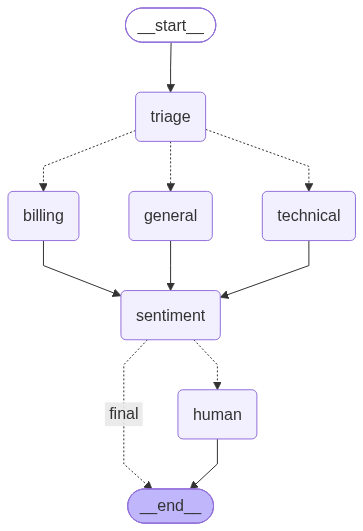

In [276]:
# ساخت نصویر
png_bytes = (graph.get_graph().draw_mermaid_png())

# ذخیره تصویر
with open("multi_agent_support_graph.png","wb") as f: f.write(png_bytes)

# نمایش تصویر
display(Image(png_bytes))

# 10. Test

این قسمت بهتره یک تابع بنویسی 

In [ ]:
# نود ۵: گاردریل احساسات و Human-in-the-Loop
def sentiment_guardrail(state: SupportState):
    if state["sentiment"] in ["NEGATIVE", "ANGRY"]:

        # گراف اینجا متوقف می‌شود و منتظر تصمیم مدیر می‌ماند.
        # هنگام resume، مقدار ارسالی در Command(resume=...) به این متغیر می‌رسد.
        manager_decision = interrupt({
            "user_message": state["user_message"],
            "sentiment": state["sentiment"],
            "draft_response": state["draft_response"],
        })

        # اعمال تصمیم مدیر
        if manager_decision["action"] == "replace":
            final_response = manager_decision["response"]
        else:
            # اگر مدیر action دیگری فرستاد، پیش‌نویس حفظ می‌شود.
            final_response = state["draft_response"]

        return {
            "final_response": final_response,
            "messages": ["[Guardrail] تصمیم مدیر اعمال شد."]
        }

    # برای لحن مثبت یا خنثی، پیش‌نویس مستقیماً تأیید می‌شود.
    return {
        "final_response": state["draft_response"],
        "messages": ["[Guardrail] پاسخ به دلیل لحن مناسب تأیید شد."]
    }


#### 1.Technical

In [ ]:
print("=" * 70)
print("TEST 1 — TECHNICAL")
print("=" * 70)

# config
technical_config = {"configurable": {"thread_id":"technical-test-001"}} # تنظیمات اجرای گراف را نگهداری می‌کند
# چون از چک پوینتر استفاده کردی این بخش لازمهست بذاری
# این بخش ذخیره نوع مکالمه است

# state
technical_state = {"messages": ["How can I reset my password?"],
                   "user_id": "",
                   "sentiment": "",
                   "department": "",
                   "next_step": "",
                   "transaction_id": "",
                   "subscription_status": "",
                   "human_response": ""}

# result
technical_result = graph.invoke(technical_state, technical_config)

print("\nDepartment:", technical_result["department"])

print("\nSentiment:", technical_result["sentiment"])

print("\nAnswer:")
print(technical_result["messages"][-1])

TEST 1 — TECHNICAL
===== ROUTE AFTER SENTIMENT =====
VALUE: 'Neutral'
GO FINAL

Department: technical

Sentiment: Neutral

Answer:
To reset your password, go to the login page and click on "Forgot Password". Enter your registered email address and a password reset link will be sent to your email. Open the link and create a new password. If you don't receive the email, check your spam folder or contact customer support for assistance.


#### 2.Billing

In [ ]:
print("=" * 70)
print("TEST 2 — BILLING")
print("=" * 70)

# config
billing_config = {"configurable": {"thread_id": "billing-test-01"}}

# state
billing_state = {"messages": ["My subscription is not working."],
                 "user_id": "12345",
                 "sentiment": "",
                 "department": "",
                 "next_step": "",
                 "transaction_id": "",
                 "subscription_status": "",
                 "human_response": ""}

# result
billing_result = graph.invoke(billing_state, billing_config) 
# دلیل Sentiment: Negative
# این بخش صرفا خروجی و اینکه به معنای اتمام گراف نیست 
# به معنای این هست که نتیجه گراف تا اون لحظه چیه
# نکته دیگری که هست اینه که پرامپت بد نوشتی که 
# My subscription is not working.
# این متن منفی ترجمه میکنه 
print("\nDepartment:", billing_result["department"])
print("\nSubscription:", billing_result["subscription_status"])
print("\nSentiment:", billing_result["sentiment"])
print("\nAnswer:")
print(billing_result["messages"][-1])

TEST 2 — BILLING
===== ROUTE AFTER SENTIMENT =====
VALUE: 'Negative'
GO HUMAN
===== HUMAN NODE EXECUTED =====
dict_keys(['messages', 'user_id', 'sentiment', 'department', 'next_step', 'transaction_id', 'subscription_status', 'human_response', '__interrupt__'])

Department: billing

Subscription: expired

Sentiment: Negative

Answer:
"Hello, I've checked on your account (12345) and it appears that your subscription has expired. Would you like to renew or cancel it?"


مشکل این کد اینه که به صورت خودکار به انسان پیام نمیده و صرفا پیام آخر میده 

#### 3.Human Escalation

In [305]:
print("=" * 70)
print("TEST 3 — HUMAN ESCALATION")
print("=" * 70)

# config
human_config = {"configurable": {"thread_id": "human-test-001"}}
# state
human_state = {"messages": ["You stole my money! This service is useless! I want to speak to a manager!"],
               "user_id": "12345",
               "sentiment": "",
               "department": "",
               "next_step": "",
               "transaction_id": "",
               "subscription_status": "",
               "human_response": ""}

# graph result
human_result = graph.invoke(human_state, human_config)

print("\nDepartment:", human_result["department"])
print("\nSubscription:", human_result["subscription_status"])
print("\nSentiment:", human_result["sentiment"])
print("\nDraft Answer:")
print(human_result["messages"][-1])

# Inspect Human State
human_snapshot = graph.get_state(human_config) 
# این قسمت یعنی کل مراحل گراف ذخیره میکنه
# فرقش با invoke: نتیجه همین اجرا میگیره ولی 

print("Saved Graph State:")
print(human_snapshot.values)

# Human Manager Response
print("\n=" * 70)
print("HUMAN MANAGER")
print("=" * 70)

manual_response = ("I am the senior manager. I apologize for the problem. I will personally follow up on your issue.")
print("\nManager response:")
print(manual_response)

# Update State
graph.update_state(human_config, {"human_response": manual_response})

# Review
updated_snapshot = graph.get_state(human_config)

print("\nUpdated state:")
print(updated_snapshot.values)

# Resume Graph
human_final_result = graph.invoke(Command(resume=manual_response), human_config)

# Final Human Response
print("\n=" * 70)
print("FINAL HUMAN RESPONSE")
print("=" * 70)

print(human_final_result["human_response"])


TEST 3 — HUMAN ESCALATION
===== ROUTE AFTER SENTIMENT =====
VALUE: 'Negative'
GO HUMAN
===== HUMAN NODE EXECUTED =====

Department: general

Subscription: 

Sentiment: Negative

Draft Answer:
I'm so sorry to hear that you're experiencing frustration with our service. I can understand why you'd feel upset, but I want to assure you that we take all concerns seriously.

Before speaking with a manager, I'd like to offer some assistance. Can you please tell me more about the issue you're experiencing? What specifically happened and how did you try to resolve it?

Additionally, I'll do my best to provide a solution or escalate your concern to a supervisor who can help you further. Your satisfaction is our top priority, and I'm here to listen and help.

Would you like me to look into this issue for you, or would you prefer to speak with a manager directly?
Saved Graph State:
{'messages': ['You stole my money! This service is useless! I want to speak to a manager!', "I'm so sorry to hear that 

In [306]:
# بررسی 
graph.invoke(Command(resume=manual_response), human_config)

{'messages': ['You stole my money! This service is useless! I want to speak to a manager!',
  "I'm so sorry to hear that you're experiencing frustration with our service. I can imagine how upsetting it must be to feel like your money has been taken advantage of.\n\nBefore we proceed, I'd like to assure you that our company takes all concerns seriously and is committed to resolving issues as quickly as possible. However, I want to clarify that making accusations without evidence can be challenging for us to address.\n\nIf you're willing, could you please provide me with more details about the issue you're experiencing? This will help me better understand your situation and see how we can assist you further. Additionally, I'll do my best to escalate your concern to a manager if needed.\n\nPlease know that I'm here to listen and help in any way I can.",
  'You stole my money! This service is useless! I want to speak to a manager!',
  "I apologize for the frustration you're experiencing. I